# 02 - RQ1 (Pandas): denial rates by geography and loan type
**HMDA 2024 project - Group 7, Member 1.** Uses the cleaned data `hmda_clean_v1`. Computes **raw** (unadjusted) denial rates by state, region, metro/non-metro, MSA and loan type, with **Wilson 95% confidence intervals**.

Denial rate = denied records / records with outcome 1, 2 or 3 (as defined in the proposal). This is a raw comparison; adjusting for loan characteristics belongs to RQ3.

## Step 1. Mount Drive and read the data

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os, time, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DRIVE_DIR  = "/content/drive/MyDrive/hmda"
CLEAN_PATH = f"{DRIVE_DIR}/hmda_clean_v1/hmda_clean_v1.parquet"
RESULTS    = f"{DRIVE_DIR}/results"
FIG_DIR    = f"{RESULTS}/figures"
os.makedirs(FIG_DIR, exist_ok=True)
assert os.path.exists(CLEAN_PATH), "hmda_clean_v1.parquet not found - run 01b first"

COLS = ["denied", "state_code", "census_region", "msa_md_clean", "metro_flag", "loan_type"]
t0 = time.perf_counter()
df = pd.read_parquet(CLEAN_PATH, columns=COLS)
t_load = time.perf_counter() - t0
print(f"Read {len(df):,} rows in {t_load:.1f}s")
assert len(df) == 3140857 and df["denied"].sum() == 276604, "Numbers do not match the cleaned data"
print("=> MATCH: 3,140,857 records, 276,604 denied")

Mounted at /content/drive
Read 3,140,857 rows in 2.9s
=> MATCH: 3,140,857 records, 276,604 denied


## Step 2. Rate and Wilson confidence-interval functions
The Wilson interval behaves better than the plain formula for small groups or rates near 0. The formula is written by hand (no library needed) so it can be read directly.

In [2]:
Z = 1.959963984540054   # 95%, exact (scipy.stats.norm.ppf(0.975)), same as notebooks 03-05

def wilson(k, n, z=Z):
    k = np.asarray(k, dtype=float); n = np.asarray(n, dtype=float)
    p = k / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / denom
    return center - half, center + half

def rate_table(data, by, min_n=1):
    g = data.groupby(by, observed=True)["denied"].agg(n="size", denied="sum").reset_index()
    g["rate"] = g["denied"] / g["n"]
    g["ci_low"], g["ci_high"] = wilson(g["denied"], g["n"])
    g = g[g["n"] >= min_n].sort_values("rate", ascending=False).reset_index(drop=True)
    return g

# check the function: 50/100 -> interval about (0.404, 0.596)
lo, hi = wilson(50, 100)
print(f"Wilson check (50/100): {float(lo):.3f} - {float(hi):.3f}  (expected ~0.404 - 0.596)")

Wilson check (50/100): 0.404 - 0.596  (expected ~0.404 - 0.596)


## Step 3. Compute the RQ1 tables

In [3]:
t0 = time.perf_counter()
overall = pd.DataFrame({"n": [len(df)], "denied": [int(df["denied"].sum())]})
overall["rate"] = overall["denied"] / overall["n"]
overall["ci_low"], overall["ci_high"] = wilson(overall["denied"], overall["n"])

df["loan_type_label"] = df["loan_type"].astype(str).map(
    {"1": "Conventional", "2": "FHA", "3": "VA", "4": "USDA RHS/FSA"}).fillna("Other")
df["metro_label"] = np.where(df["metro_flag"] == 1, "Metro", "Non-metro")

# Records WITHOUT a state (state_code = "NA") have a very high denial rate -> kept separate, not part of the state/region tables or the map
state_missing = df[df["state_code"] == "NA"]
df_geo = df[df["state_code"] != "NA"]
print(f"Records without a state: {len(state_missing):,} ({len(state_missing)/len(df):.2%}), denial rate {state_missing['denied'].mean():.2%}")
by_state  = rate_table(df_geo, "state_code")
by_region = rate_table(df_geo, "census_region")
by_metro  = rate_table(df, "metro_label")
by_loan   = rate_table(df, "loan_type_label")
by_msa    = rate_table(df, "msa_md_clean", min_n=5000)      # every MSA with >= 5,000 records
major_ids = (df[df["metro_flag"] == 1].groupby("msa_md_clean", observed=True).size().nlargest(20).index)
by_msa_major = by_msa[by_msa["msa_md_clean"].isin(major_ids)].reset_index(drop=True)   # the 20 largest MSAs by number of records
t_compute = time.perf_counter() - t0
print(f"Computed in {t_compute:.1f}s (data load: {t_load:.1f}s) - keep these for the benchmark")

# Check: the group totals must equal the overall total
for name, t in [("state", by_state), ("region", by_region)]:
    assert t["n"].sum() + len(state_missing) == len(df), f"{name}: totals do not match"
for name, t in [("metro", by_metro), ("loan_type", by_loan)]:
    assert t["n"].sum() == len(df) and t["denied"].sum() == df["denied"].sum(), f"{name}: totals do not match"
print("=> All group totals match the overall total")
print(f"Overall denial rate: {overall['rate'][0]:.2%}  (95% CI {overall['ci_low'][0]:.2%} - {overall['ci_high'][0]:.2%})")

Records without a state: 8,026 (0.26%), denial rate 65.23%
Computed in 1.3s (data load: 2.9s) - keep these for the benchmark
=> All group totals match the overall total
Overall denial rate: 8.81%  (95% CI 8.78% - 8.84%)


## Step 4. View the results

In [4]:
fmt = {"rate": "{:.2%}", "ci_low": "{:.2%}", "ci_high": "{:.2%}", "n": "{:,}", "denied": "{:,}"}
print("=== By region ===");        display(by_region.style.format(fmt))
print("=== Metro / Non-metro ==="); display(by_metro.style.format(fmt))
print("=== By loan type ==="); display(by_loan.style.format(fmt))
print("=== 10 highest states ===");  display(by_state.head(10).style.format(fmt))
print("=== 10 lowest states ===");   display(by_state.tail(10).style.format(fmt))
main = by_state[~by_state["state_code"].isin(["PR", "VI", "GU", "AS", "MP"])]     # 50 states + DC
print(f"Gap between the highest ({main.iloc[0]['state_code']}) and lowest ({main.iloc[-1]['state_code']}) state: "
            f"{(main['rate'].max() - main['rate'].min())*100:.2f} percentage points (50 states + DC)")

=== By region ===


,census_region,n,denied,rate,ci_low,ci_high
0,Territory,"12,890","2,496",19.36%,18.69%,20.06%
1,South,"1,397,598","134,263",9.61%,9.56%,9.66%
2,Northeast,"401,336","33,901",8.45%,8.36%,8.53%
3,West,"654,252","50,595",7.73%,7.67%,7.80%
4,Midwest,"666,755","50,114",7.52%,7.45%,7.58%


=== Metro / Non-metro ===


,metro_label,n,denied,rate,ci_low,ci_high
0,Non-metro,"337,518","38,118",11.29%,11.19%,11.40%
1,Metro,"2,803,339","238,486",8.51%,8.47%,8.54%


=== By loan type ===


,loan_type_label,n,denied,rate,ci_low,ci_high
0,FHA,"681,178","85,261",12.52%,12.44%,12.60%
1,USDA RHS/FSA,"37,042","4,404",11.89%,11.56%,12.22%
2,VA,"339,673","27,750",8.17%,8.08%,8.26%
3,Conventional,"2,082,964","159,189",7.64%,7.61%,7.68%


=== 10 highest states ===


,state_code,n,denied,rate,ci_low,ci_high
0,PR,"12,763","2,483",19.45%,18.78%,20.15%
1,VI,21,3,14.29%,4.98%,34.64%
2,FL,"273,741","35,765",13.07%,12.94%,13.19%
3,MS,"22,059","2,560",11.61%,11.19%,12.03%
4,LA,"33,117","3,503",10.58%,10.25%,10.91%
5,HI,"8,005",846,10.57%,9.91%,11.26%
6,NY,"105,410","10,697",10.15%,9.97%,10.33%
7,WV,"13,833","1,338",9.67%,9.19%,10.18%
8,TX,"335,694","32,342",9.63%,9.54%,9.73%
9,GA,"117,945","11,236",9.53%,9.36%,9.70%


=== 10 lowest states ===


,state_code,n,denied,rate,ci_low,ci_high
44,WI,"52,597","3,528",6.71%,6.50%,6.92%
45,ND,"6,928",459,6.63%,6.06%,7.24%
46,UT,"38,590","2,540",6.58%,6.34%,6.83%
47,CO,"72,662","4,672",6.43%,6.25%,6.61%
48,AK,"6,881",435,6.32%,5.77%,6.92%
49,NE,"18,863","1,187",6.29%,5.96%,6.65%
50,WA,"73,763","4,630",6.28%,6.10%,6.45%
51,OR,"37,794","2,140",5.66%,5.43%,5.90%
52,ID,"22,533","1,253",5.56%,5.27%,5.87%
53,MN,"56,827","3,065",5.39%,5.21%,5.58%


Gap between the highest (FL) and lowest (MN) state: 7.67 percentage points (50 states + DC)


## Step 5. Figures
One shared style for every figure (the Group 7 color system used in notebooks 03-05: red-orange = above or denied, amber = below or comparison, grey = no difference; heatmaps use the warm scale). Bar color shows whether a group's 95% interval lies **above** (red-orange), **below** (amber) or **overlaps** (grey) the overall denial rate, so the reader sees at a glance which differences are real. The reference line is the pooled rate of the units being compared: all records (8.81%) for loan type, metro status, region and metropolitan areas; the 50 states + DC (8.62%) for states, because territories and records without a state are not part of the state comparison.

In [5]:
import textwrap
import matplotlib as mpl
from matplotlib.patches import Patch, Rectangle

from matplotlib.colors import LinearSegmentedColormap
import logging
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)   # DejaVu has no 'semibold' file: Matplotlib draws bold

# GROUP 7 - OFFICIAL COLOR SYSTEM (same as notebooks 03-05)
COLORS = {"amber": "#F6AE2D", "orange": "#F28C28", "terracotta": "#E4572E", "denied": "#D94F30", "deep_red": "#B83227",
          "burgundy": "#8C2F39", "cream": "#FFF9F2", "text": "#422A24", "secondary": "#77665F", "grid": "#EADFD5",
          "missing": "#B8B8B8", "white": "#FFFFFF"}
HEATMAP_CMAP = LinearSegmentedColormap.from_list("group7_warm", ["#FFF4E6", "#FFD58A", "#F6AE2D", "#F28C28", "#E4572E", "#B83227"])
TXT, SEC = COLORS["text"], COLORS["secondary"]
mpl.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11, "axes.titlesize": 16, "axes.titleweight": "bold",
                     "axes.labelsize": 12, "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10,
                     "figure.dpi": 120, "savefig.dpi": 300, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": COLORS["grid"], "axes.labelcolor": TXT, "text.color": TXT,
                     "xtick.color": SEC, "ytick.color": SEC, "figure.facecolor": COLORS["white"],
                     "axes.facecolor": COLORS["white"], "axes.grid": True, "grid.color": COLORS["grid"],
                     "grid.linewidth": 0.8, "axes.axisbelow": True})
NAT = float(overall["rate"][0])
C_HI, C_LO, C_NS = COLORS["denied"], COLORS["amber"], COLORS["missing"]   # above reference: red-orange; below: amber; not different: grey
SOURCE = textwrap.fill("Source: 2024 HMDA public LAR; single-family site-built, owner-occupied, first-lien home-purchase "
                       "applications with outcome originated, approved-not-accepted or denied. "
                       "Raw (unadjusted) rates.", 120)
TERRITORIES = ["PR", "VI", "GU", "AS", "MP"]
_st = by_state[~by_state["state_code"].isin(TERRITORIES)]
NAT_ST = float(_st["denied"].sum() / _st["n"].sum())      # pooled rate of the 50 states + DC: the reference for state comparisons
if len(df) == 3140857:
    assert int(_st["n"].sum()) == 3119941, "50 states + DC should hold 3,119,941 records"
print(f"Reference rates: all records {NAT:.2%} | 50 states + DC {NAT_ST:.2%} (territories and records without a state are left out of the second)")
LEGEND = [Patch(color=C_HI, label="Above reference rate (95% CI)"), Patch(color=C_NS, label="Not different from reference"),
          Patch(color=C_LO, label="Below reference rate (95% CI)")]

def sig_colors(t, ref=None):
    ref = NAT if ref is None else ref
    return np.where(t["ci_low"] > ref, C_HI, np.where(t["ci_high"] < ref, C_LO, C_NS))

def footnote(ax, extra="", dy=-42):
    ax.annotate(SOURCE + extra, xy=(0, 0), xycoords="axes fraction", xytext=(0, dy), textcoords="offset points",
                fontsize=9, color=SEC, ha="left", va="top")

def save(fig, fname):
    fig.savefig(f"{FIG_DIR}/{fname}", bbox_inches="tight", facecolor="white")
    plt.show()

def bar_ci(t, label_col, title, fname, top=None, label_fn=None, min_n=None, ref=None, ref_label="overall"):
    ref = NAT if ref is None else ref
    d = t if min_n is None else t[t["n"] >= min_n]
    d = (d.head(top) if top else d).iloc[::-1]
    labels = [label_fn(x) if label_fn else str(x) for x in d[label_col]]
    fig, ax = plt.subplots(figsize=(9, max(2.6, 0.27 * len(d) + 1.6)))
    y = np.arange(len(d))
    ax.barh(y, d["rate"] * 100, color=sig_colors(d, ref), height=0.72,
            xerr=[(d["rate"] - d["ci_low"]) * 100, (d["ci_high"] - d["rate"]) * 100],
            error_kw={"ecolor": TXT, "elinewidth": 1, "capsize": 2})
    for yi, (r, hi, n) in enumerate(zip(d["rate"], d["ci_high"], d["n"])):
        ax.text(hi * 100 + 0.012 * d["ci_high"].max() * 100, yi, f"{r:.1%}  (n={n:,})", va="center", fontsize=10, fontweight="semibold", color=TXT)
    ax.axvline(ref * 100, color=TXT, ls="--", lw=1)
    ax.set_ylim(-0.6, len(d) + 0.4)                     # one free row above the top bar for the reference label
    ax.text(ref * 100, len(d) - 0.35, f" {ref_label} {ref:.2%}", fontsize=10, va="bottom", ha="left", color=TXT)
    ax.set_yticks(y); ax.set_yticklabels(labels); ax.set_xlabel("Denial rate (%)", fontsize=12)
    ax.set_xlim(0, d["ci_high"].max() * 100 * 1.3)
    ax.set_title(title, loc="left"); ax.grid(axis="y", visible=False)
    ax.legend(handles=LEGEND, loc="upper left", bbox_to_anchor=(1.01, 1.0), fontsize=10, frameon=False)   # outside: never covers a bar label
    footnote(ax, " Error bars: Wilson 95% CI.")
    save(fig, fname)

Reference rates: all records 8.81% | 50 states + DC 8.62% (territories and records without a state are left out of the second)


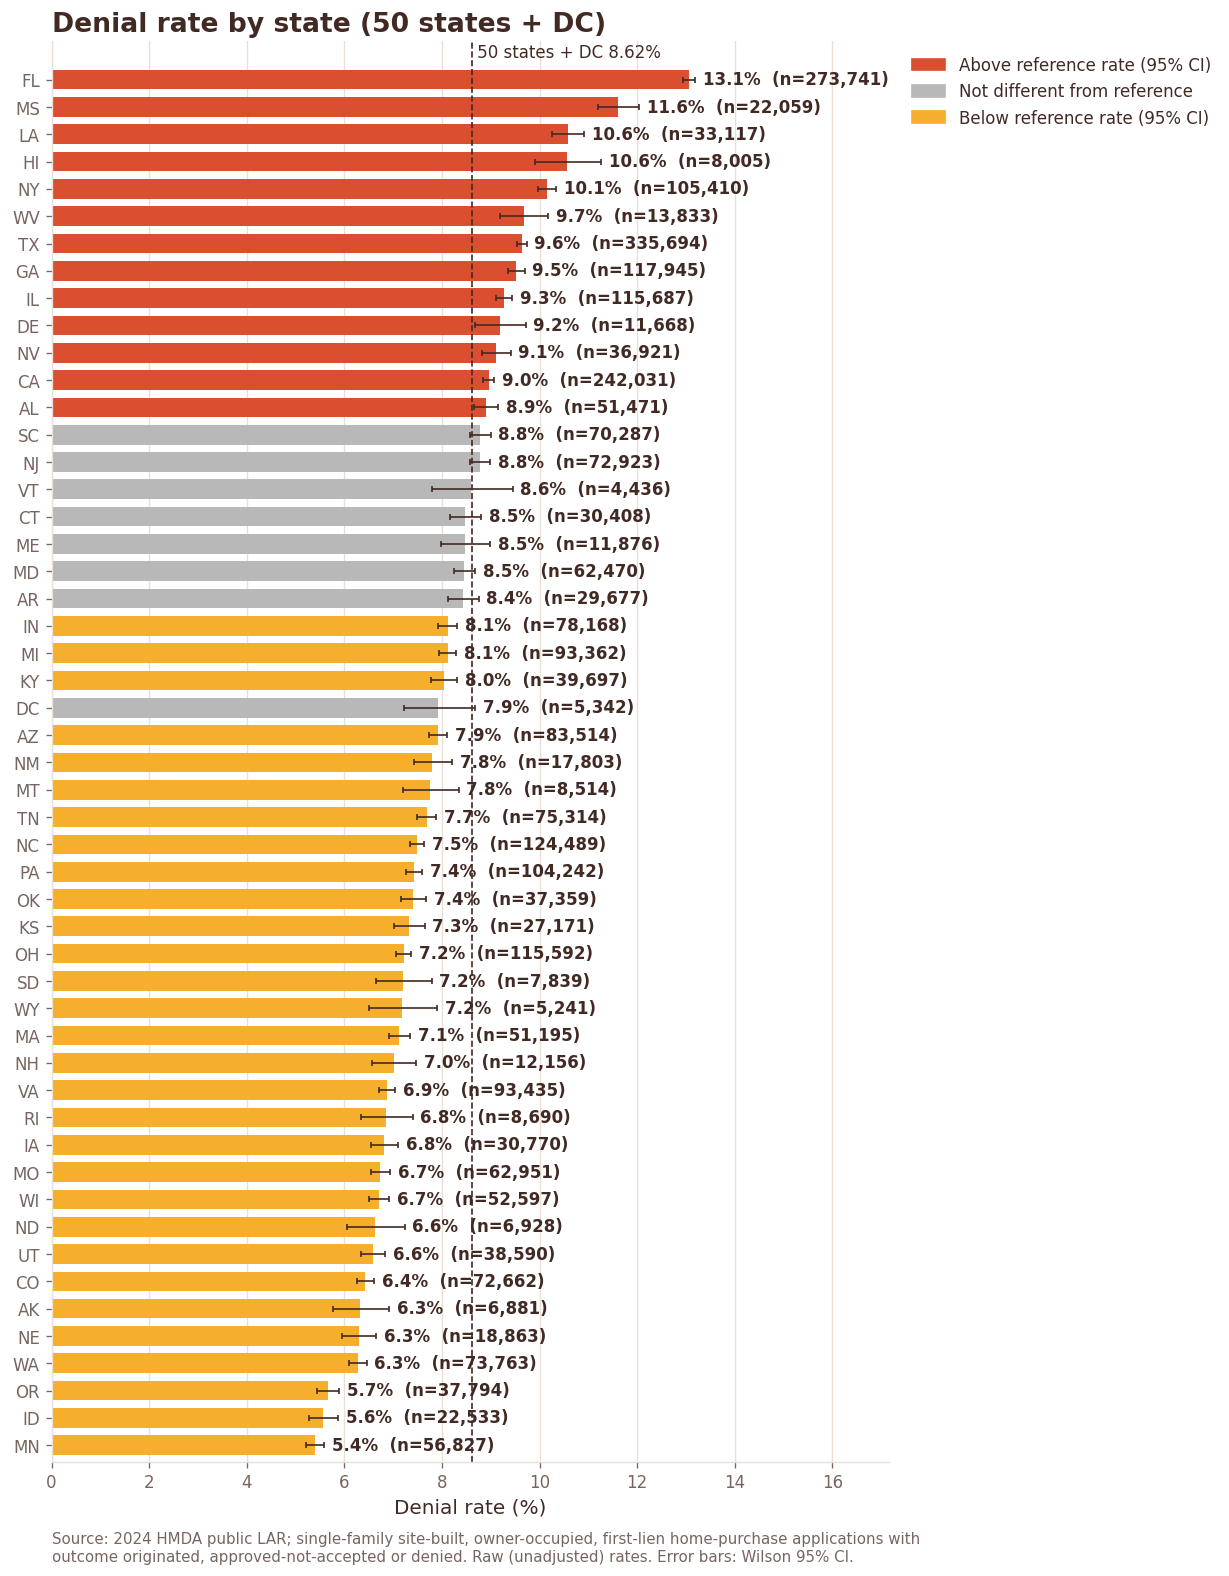

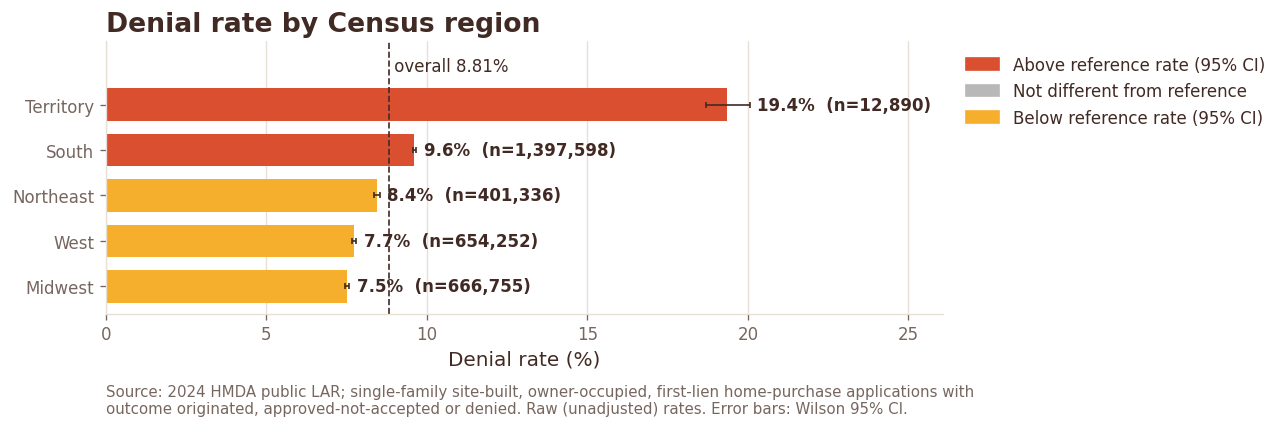

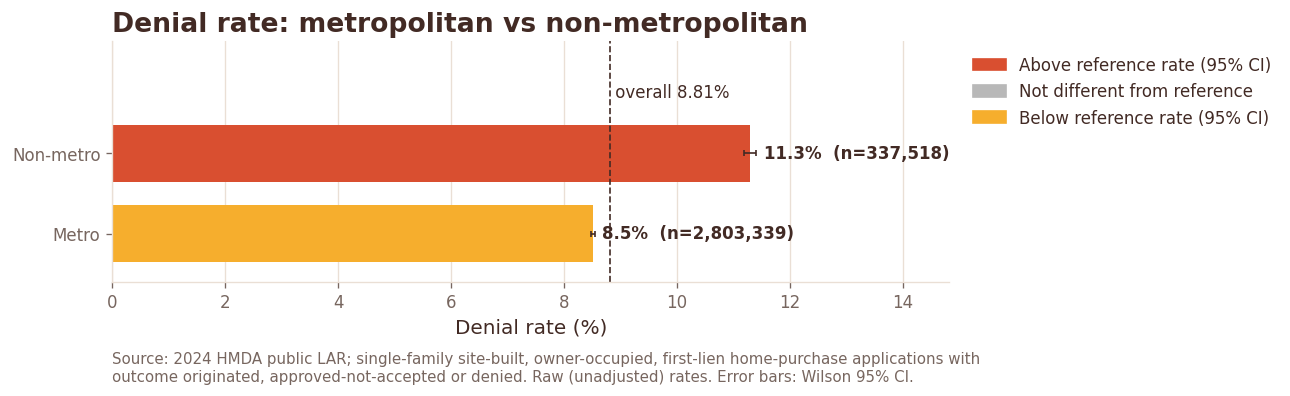

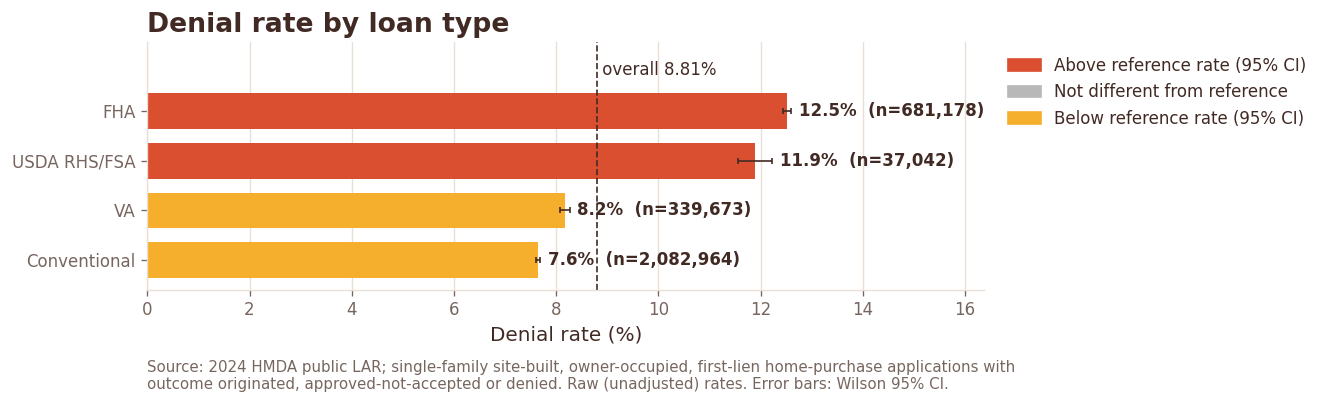

In [6]:
states_only = by_state[~by_state["state_code"].isin(TERRITORIES)]      # 50 states + DC (territories reported separately)
bar_ci(states_only, "state_code", "Denial rate by state (50 states + DC)", "rq1_state.png", ref=NAT_ST, ref_label="50 states + DC")
bar_ci(by_region, "census_region", "Denial rate by Census region", "rq1_region.png")
bar_ci(by_metro, "metro_label", "Denial rate: metropolitan vs non-metropolitan", "rq1_metro.png")
bar_ci(by_loan, "loan_type_label", "Denial rate by loan type", "rq1_loan_type.png")

## Step 5a. State tile-grid map (static, for the report)
Each tile is one state, colored by denial rate. A tile grid gives every state equal visual weight, so small states such as DC or RI are not hidden. It needs no map files, so it always renders and is saved as a PNG.

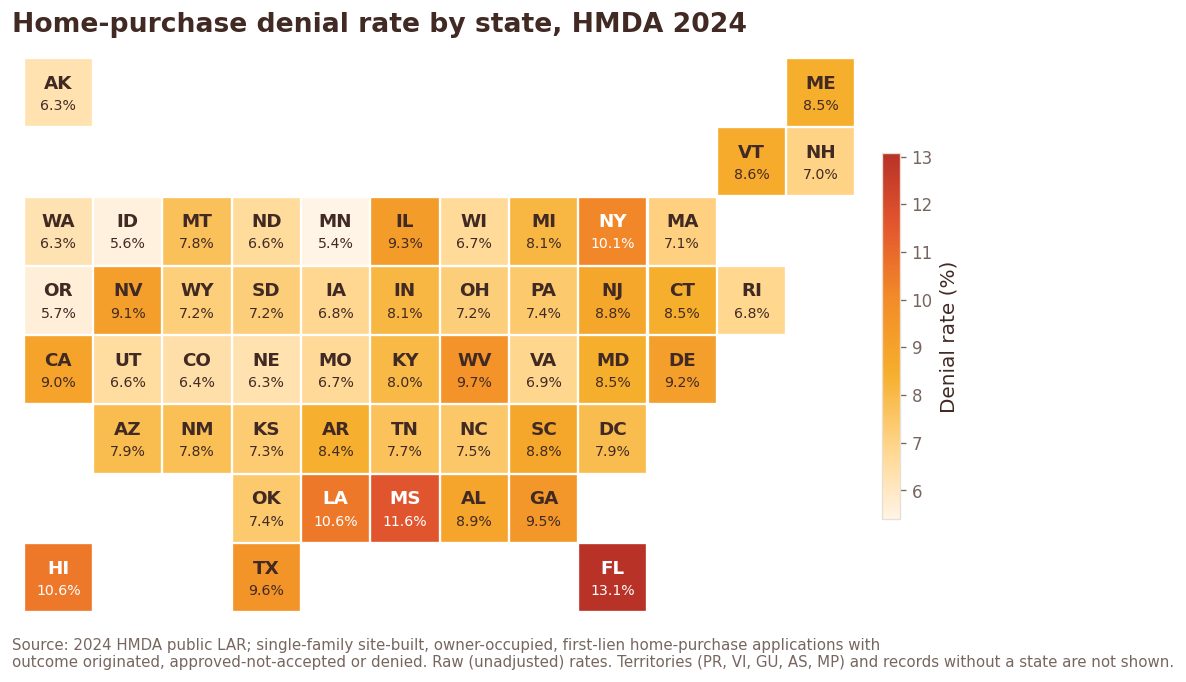

In [7]:
GRID = {"AK": (0, 0), "ME": (0, 11), "VT": (1, 10), "NH": (1, 11),
        "WA": (2, 0), "ID": (2, 1), "MT": (2, 2), "ND": (2, 3), "MN": (2, 4), "IL": (2, 5), "WI": (2, 6), "MI": (2, 7), "NY": (2, 8), "MA": (2, 9),
        "OR": (3, 0), "NV": (3, 1), "WY": (3, 2), "SD": (3, 3), "IA": (3, 4), "IN": (3, 5), "OH": (3, 6), "PA": (3, 7), "NJ": (3, 8), "CT": (3, 9), "RI": (3, 10),
        "CA": (4, 0), "UT": (4, 1), "CO": (4, 2), "NE": (4, 3), "MO": (4, 4), "KY": (4, 5), "WV": (4, 6), "VA": (4, 7), "MD": (4, 8), "DE": (4, 9),
        "AZ": (5, 1), "NM": (5, 2), "KS": (5, 3), "AR": (5, 4), "TN": (5, 5), "NC": (5, 6), "SC": (5, 7), "DC": (5, 8),
        "OK": (6, 3), "LA": (6, 4), "MS": (6, 5), "AL": (6, 6), "GA": (6, 7),
        "HI": (7, 0), "TX": (7, 3), "FL": (7, 8)}
rates = states_only.set_index("state_code")["rate"] * 100
vmin, vmax = rates.min(), rates.max()
cmap = HEATMAP_CMAP
norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)

fig, ax = plt.subplots(figsize=(11, 6.6))
for st, (r, c) in GRID.items():
    if st not in rates.index:
        continue
    v = rates[st]
    ax.add_patch(Rectangle((c, -r), 0.94, 0.94, color=cmap(norm(v))))
    txt_color = "white" if norm(v) > 0.6 else TXT
    ax.text(c + 0.47, -r + 0.6, st, ha="center", va="center", fontsize=11, fontweight="bold", color=txt_color)
    ax.text(c + 0.47, -r + 0.28, f"{v:.1f}%", ha="center", va="center", fontsize=8.5, color=txt_color)
ax.set_xlim(-0.2, 12.2); ax.set_ylim(-7.3, 1.2); ax.set_aspect("equal"); ax.axis("off")
ax.set_title("Home-purchase denial rate by state, HMDA 2024", loc="left")
cb = fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=ax, shrink=0.6, pad=0.01)
cb.set_label("Denial rate (%)")
footnote(ax, " Territories (PR, VI, GU, AS, MP) and records without a state are not shown.", dy=-4)
save(fig, "rq1_state_tilemap.png")

## Step 5b. Funnel plot: which states differ from the 50-state rate beyond chance?
Small states have noisy rates, so a raw ranking can mislead. A funnel plot compares every state with the pooled rate of the 50 states + DC (the population being compared) **given its sample size**: states outside the dashed 99.8% limits differ from that rate by more than sampling noise would explain. This is still descriptive (RQ3 asks *why*).

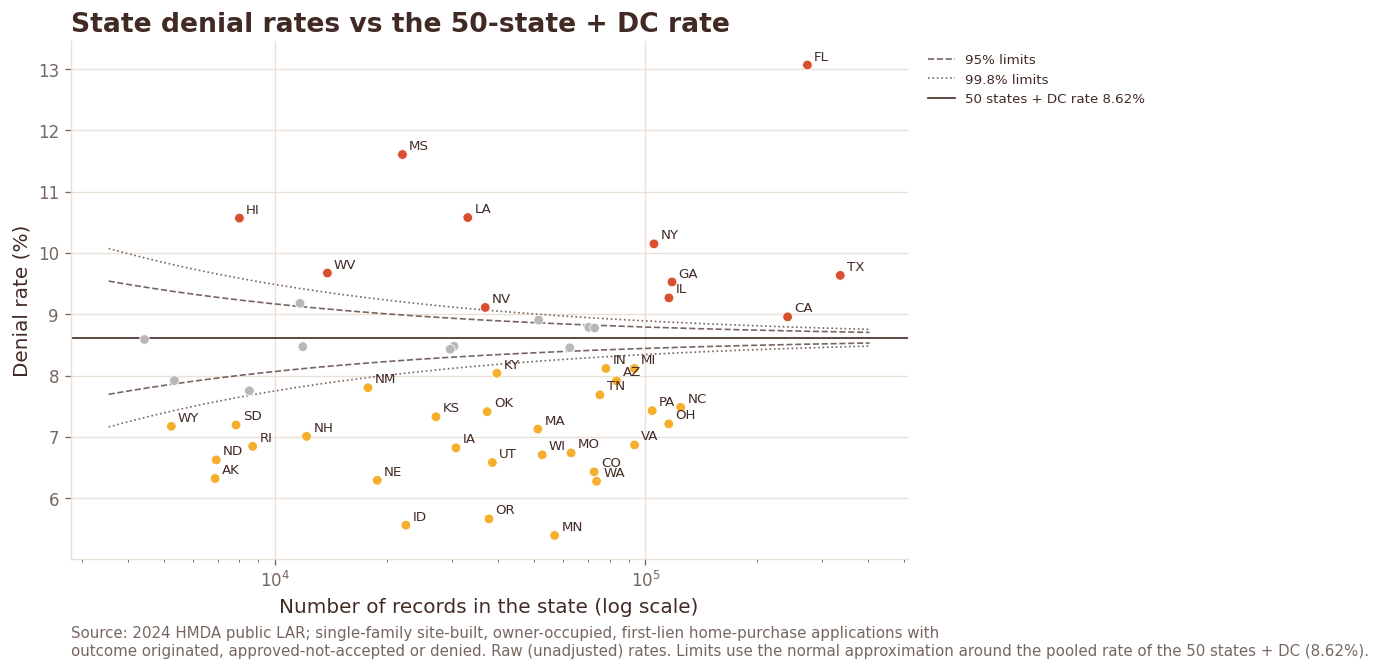

11 states above and 29 below the 50-state + DC rate beyond the 99.8% limits (of 51 states + DC)
Above: ['FL', 'MS', 'LA', 'HI', 'NY', 'WV', 'TX', 'GA', 'IL', 'NV', 'CA'] | Below: ['IN', 'MI', 'KY', 'AZ', 'NM', 'TN', 'NC', 'PA', 'OK', 'KS', 'OH', 'SD', 'WY', 'MA', 'NH', 'VA', 'RI', 'IA', 'MO', 'WI', 'ND', 'UT', 'CO', 'AK', 'NE', 'WA', 'OR', 'ID', 'MN']


In [8]:
s = states_only.copy()
z95, z998 = 1.959964, 3.090232
se = np.sqrt(NAT_ST * (1 - NAT_ST) / s["n"])
s["out_hi"] = s["rate"] > NAT_ST + z998 * se
s["out_lo"] = s["rate"] < NAT_ST - z998 * se

fig, ax = plt.subplots(figsize=(9, 5.6))
xs = np.logspace(np.log10(s["n"].min() * 0.8), np.log10(s["n"].max() * 1.2), 200)
for z, ls, lab in [(z95, "--", "95% limits"), (z998, ":", "99.8% limits")]:
    sx = np.sqrt(NAT_ST * (1 - NAT_ST) / xs)
    ax.plot(xs, (NAT_ST + z * sx) * 100, color=SEC, ls=ls, lw=1, label=lab)
    ax.plot(xs, (NAT_ST - z * sx) * 100, color=SEC, ls=ls, lw=1)
ax.axhline(NAT_ST * 100, color=TXT, lw=1, label=f"50 states + DC rate {NAT_ST:.2%}")
cols = np.where(s["out_hi"], C_HI, np.where(s["out_lo"], C_LO, C_NS))
ax.scatter(s["n"], s["rate"] * 100, c=cols, s=34, zorder=3, edgecolor="white", linewidth=0.5)
for _, r in s[s["out_hi"] | s["out_lo"]].iterrows():
    ax.annotate(r["state_code"], (r["n"], r["rate"] * 100), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.set_xscale("log"); ax.set_xlabel("Number of records in the state (log scale)"); ax.set_ylabel("Denial rate (%)")
ax.set_title("State denial rates vs the 50-state + DC rate", loc="left")
ax.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0))
footnote(ax, f" Limits use the normal approximation around the pooled rate of the 50 states + DC ({NAT_ST:.2%}).", dy=-40)
save(fig, "rq1_state_funnel.png")
print(f"{int(s['out_hi'].sum())} states above and {int(s['out_lo'].sum())} below the 50-state + DC rate beyond the 99.8% limits "
      f"(of {len(s)} states + DC)")
print("Above:", list(s.loc[s['out_hi'], 'state_code']), "| Below:", list(s.loc[s['out_lo'], 'state_code']))

## Step 5c. Does the loan-type pattern hold in every region?
Region x loan type denial rates. If FHA is above conventional in every region, the loan-type gap is not an artifact of geography.

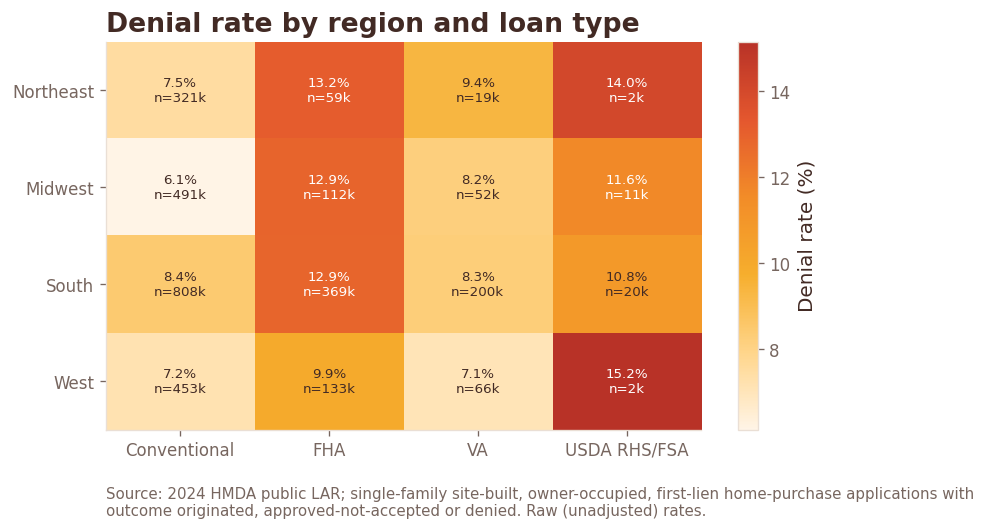

In [9]:
cross = (df_geo[df_geo["census_region"] != "Unknown"]
         .groupby(["census_region", "loan_type_label"], observed=True)["denied"].agg(n="size", denied="sum").reset_index())
cross["rate"] = cross["denied"] / cross["n"]
rows = ["Northeast", "Midwest", "South", "West"]      # territories excluded: their very high rates would wash out the color scale
colsl = ["Conventional", "FHA", "VA", "USDA RHS/FSA"]
pt = cross.pivot(index="census_region", columns="loan_type_label", values="rate").reindex(index=rows, columns=colsl)
pn = cross.pivot(index="census_region", columns="loan_type_label", values="n").reindex(index=rows, columns=colsl)

fig, ax = plt.subplots(figsize=(8, 4.2))
im = ax.imshow(pt.values * 100, cmap=HEATMAP_CMAP, aspect="auto")
ax.set_xticks(range(len(colsl))); ax.set_xticklabels(colsl); ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows)
ax.grid(False)
for i in range(len(rows)):
    for j in range(len(colsl)):
        v, n = pt.values[i, j], pn.values[i, j]
        if np.isnan(v):
            continue
        ax.text(j, i, f"{v:.1%}\nn={n/1000:,.0f}k", ha="center", va="center", fontsize=8,
                color="white" if im.norm(v * 100) > 0.6 else TXT)
fig.colorbar(im, ax=ax, label="Denial rate (%)")
ax.set_title("Denial rate by region and loan type", loc="left")
footnote(ax, dy=-34)
save(fig, "rq1_region_by_loan_type.png")

## Step 5d. Metropolitan areas
HMDA gives only the MSA/MD **code**. To make the charts readable, names are looked up from the official Census Bureau CBSA delineation file (July 2023 delineations, the ones used for 2024 HMDA). This lookup only **labels** the codes; it adds no data to any calculation. If the download fails, the charts fall back to codes. Metropolitan areas in territories (San Juan, PR) are reported in the table but left out of the ranking charts, in line with the state comparison.

Loaded 972 CBSA / division names from the Census Bureau file
MSAs with n >= 5,000: 133 on the US mainland, Alaska and Hawaii (+ 1 in territories, left out of the ranking) + the Non-metro group


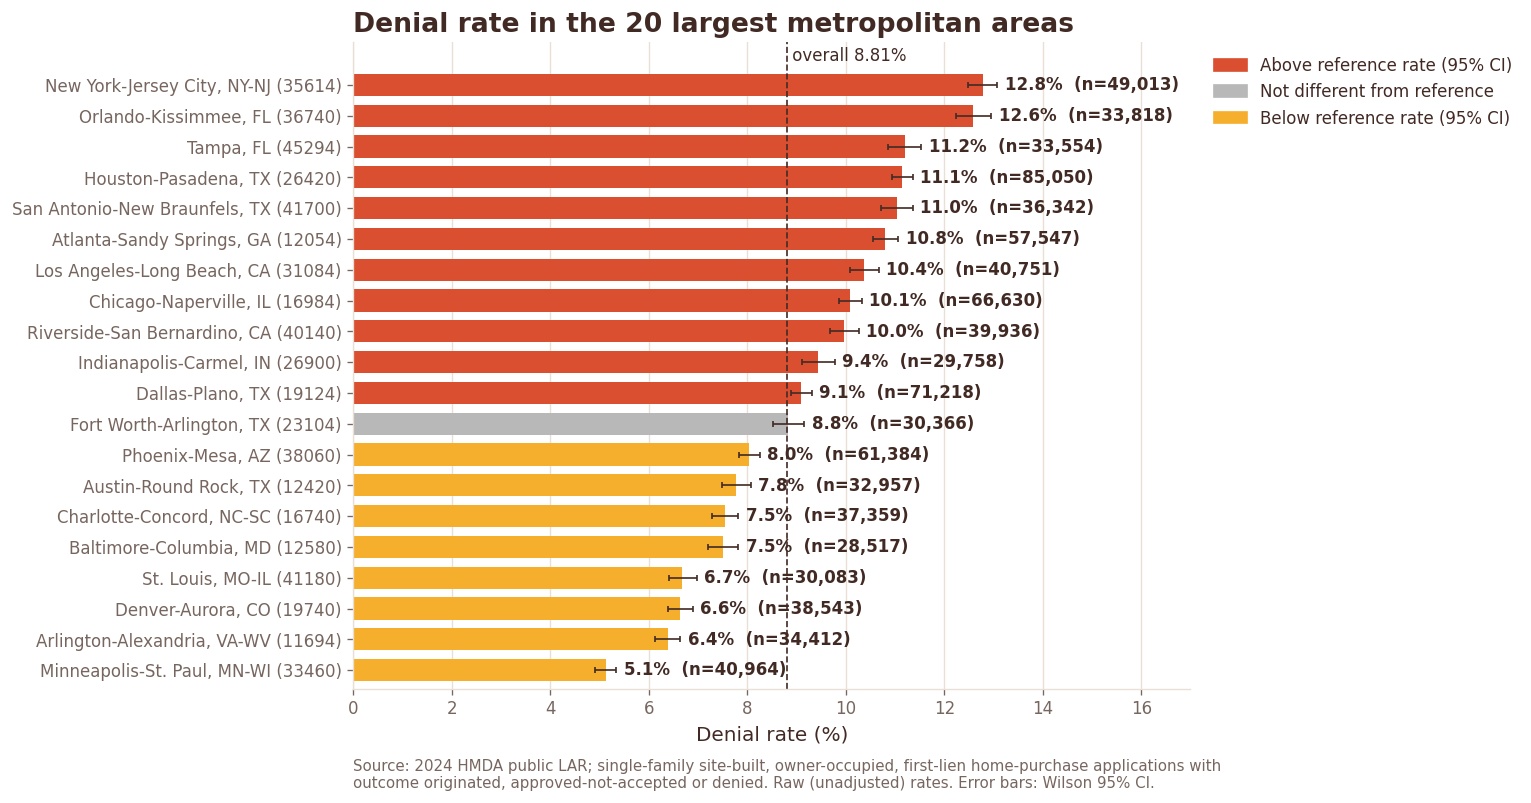

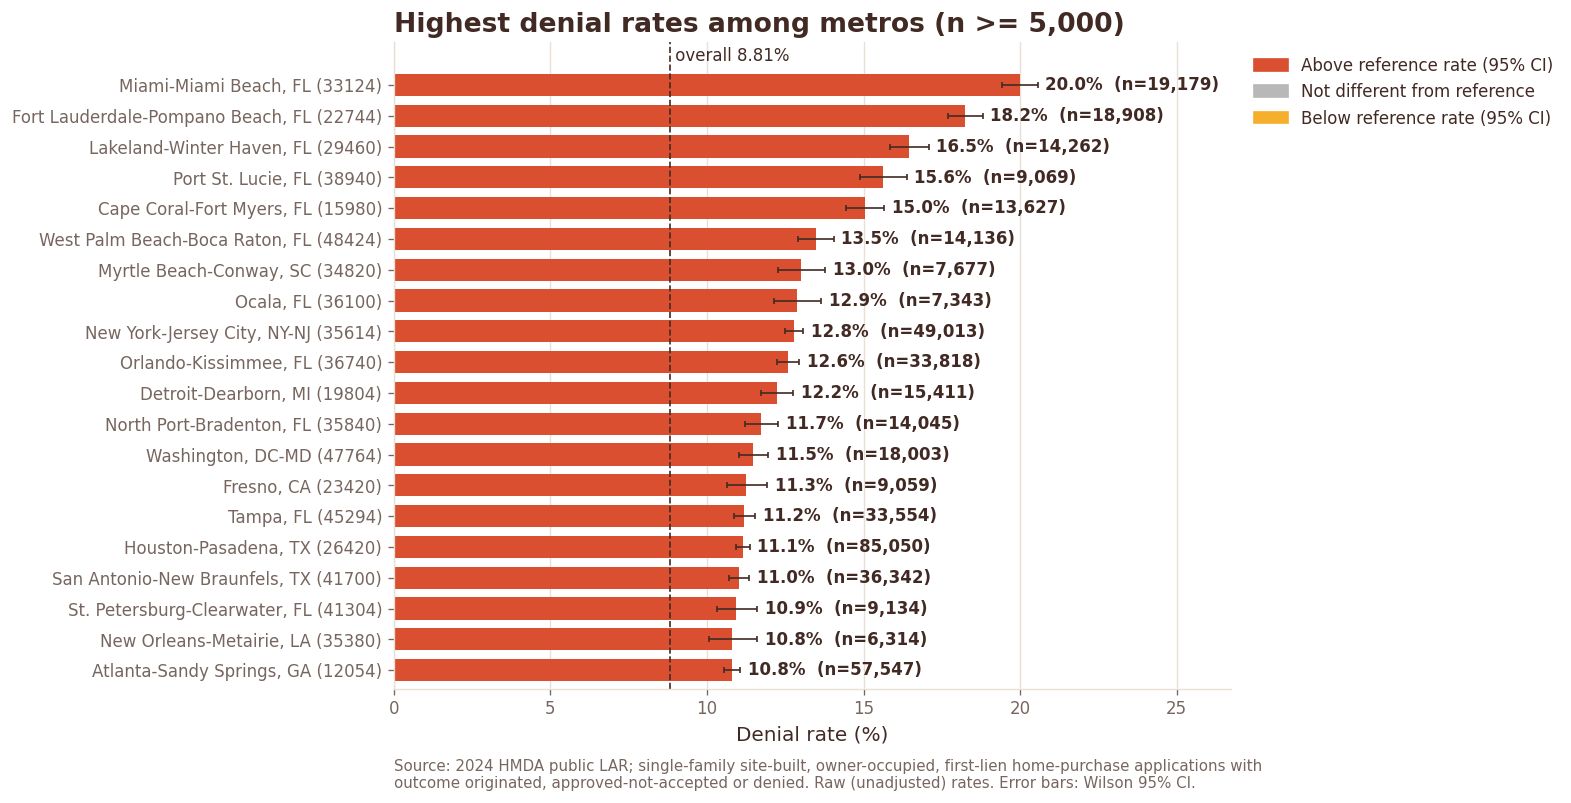

In [10]:
msa_names = {}
try:
    url = ("https://www2.census.gov/programs-surveys/metro-micro/geographies/reference-files/"
           "2023/delineation-files/list1_2023.xlsx")
    d = pd.read_excel(url, header=2, dtype=str)
    d.columns = [str(c).strip() for c in d.columns]
    for code_col, title_col in [("CBSA Code", "CBSA Title"), ("Metropolitan Division Code", "Metropolitan Division Title")]:
        sub = d[[code_col, title_col]].dropna()
        msa_names.update(dict(zip(sub[code_col].str.strip(), sub[title_col].str.strip())))
    print(f"Loaded {len(msa_names):,} CBSA / division names from the Census Bureau file")
except Exception as e:
    print("MSA names not loaded - charts will show codes only:", str(e)[:100])

def msa_label(c):
    """'New York-Jersey City-White Plains, NY-NJ' -> 'New York-Jersey City, NY-NJ (35614)'"""
    c = str(c)
    if c not in msa_names:
        return c
    cities, sep, states = msa_names[c].rpartition(", ")
    if not sep:
        return f"{msa_names[c][:40]} ({c})"
    return f"{'-'.join(cities.split('-')[:2])}, {states} ({c})"

for t in (by_msa, by_msa_major):
    t["msa_name"] = t["msa_md_clean"].astype(str).map(msa_names)
# Territories (e.g. San Juan, PR) are reported separately everywhere, as in the state comparison: left out of the metro ranking (still in rq1_by_msa.csv)
_share_terr = (df["census_region"].astype(str) == "Territory").groupby(df["msa_md_clean"].astype(str)).mean()
terr_msas = set(_share_terr[_share_terr > 0.5].index) - {"Non-metro"}     # an MSA is a territory MSA if most of its records are in a territory
by_msa_metro = by_msa[(by_msa["msa_md_clean"] != "Non-metro") & ~by_msa["msa_md_clean"].astype(str).isin(terr_msas)]
print(f"MSAs with n >= 5,000: {len(by_msa_metro)} on the US mainland, Alaska and Hawaii (+ {len(terr_msas & set(by_msa['msa_md_clean'].astype(str)))} in territories, left out of the ranking) + the Non-metro group")
bar_ci(by_msa_major, "msa_md_clean", "Denial rate in the 20 largest metropolitan areas",
       "rq1_msa_major20.png", label_fn=msa_label)
bar_ci(by_msa_metro, "msa_md_clean", "Highest denial rates among metros (n >= 5,000)",
       "rq1_msa_top20_rate.png", top=20, label_fn=msa_label, min_n=5000)

## Step 5f. One-page panel for the report
Five panels in one image: **A** state tile map, **B** funnel plot (which states differ beyond chance), **C** loan type, metro status and region, **D** region by loan type, **E** the 20 largest metropolitan areas. This is the figure to put in the report (`rq1_panel.png`); the figures above stay as supplementary material. Run Steps 5 to 5d first, because the panel reuses their variables.

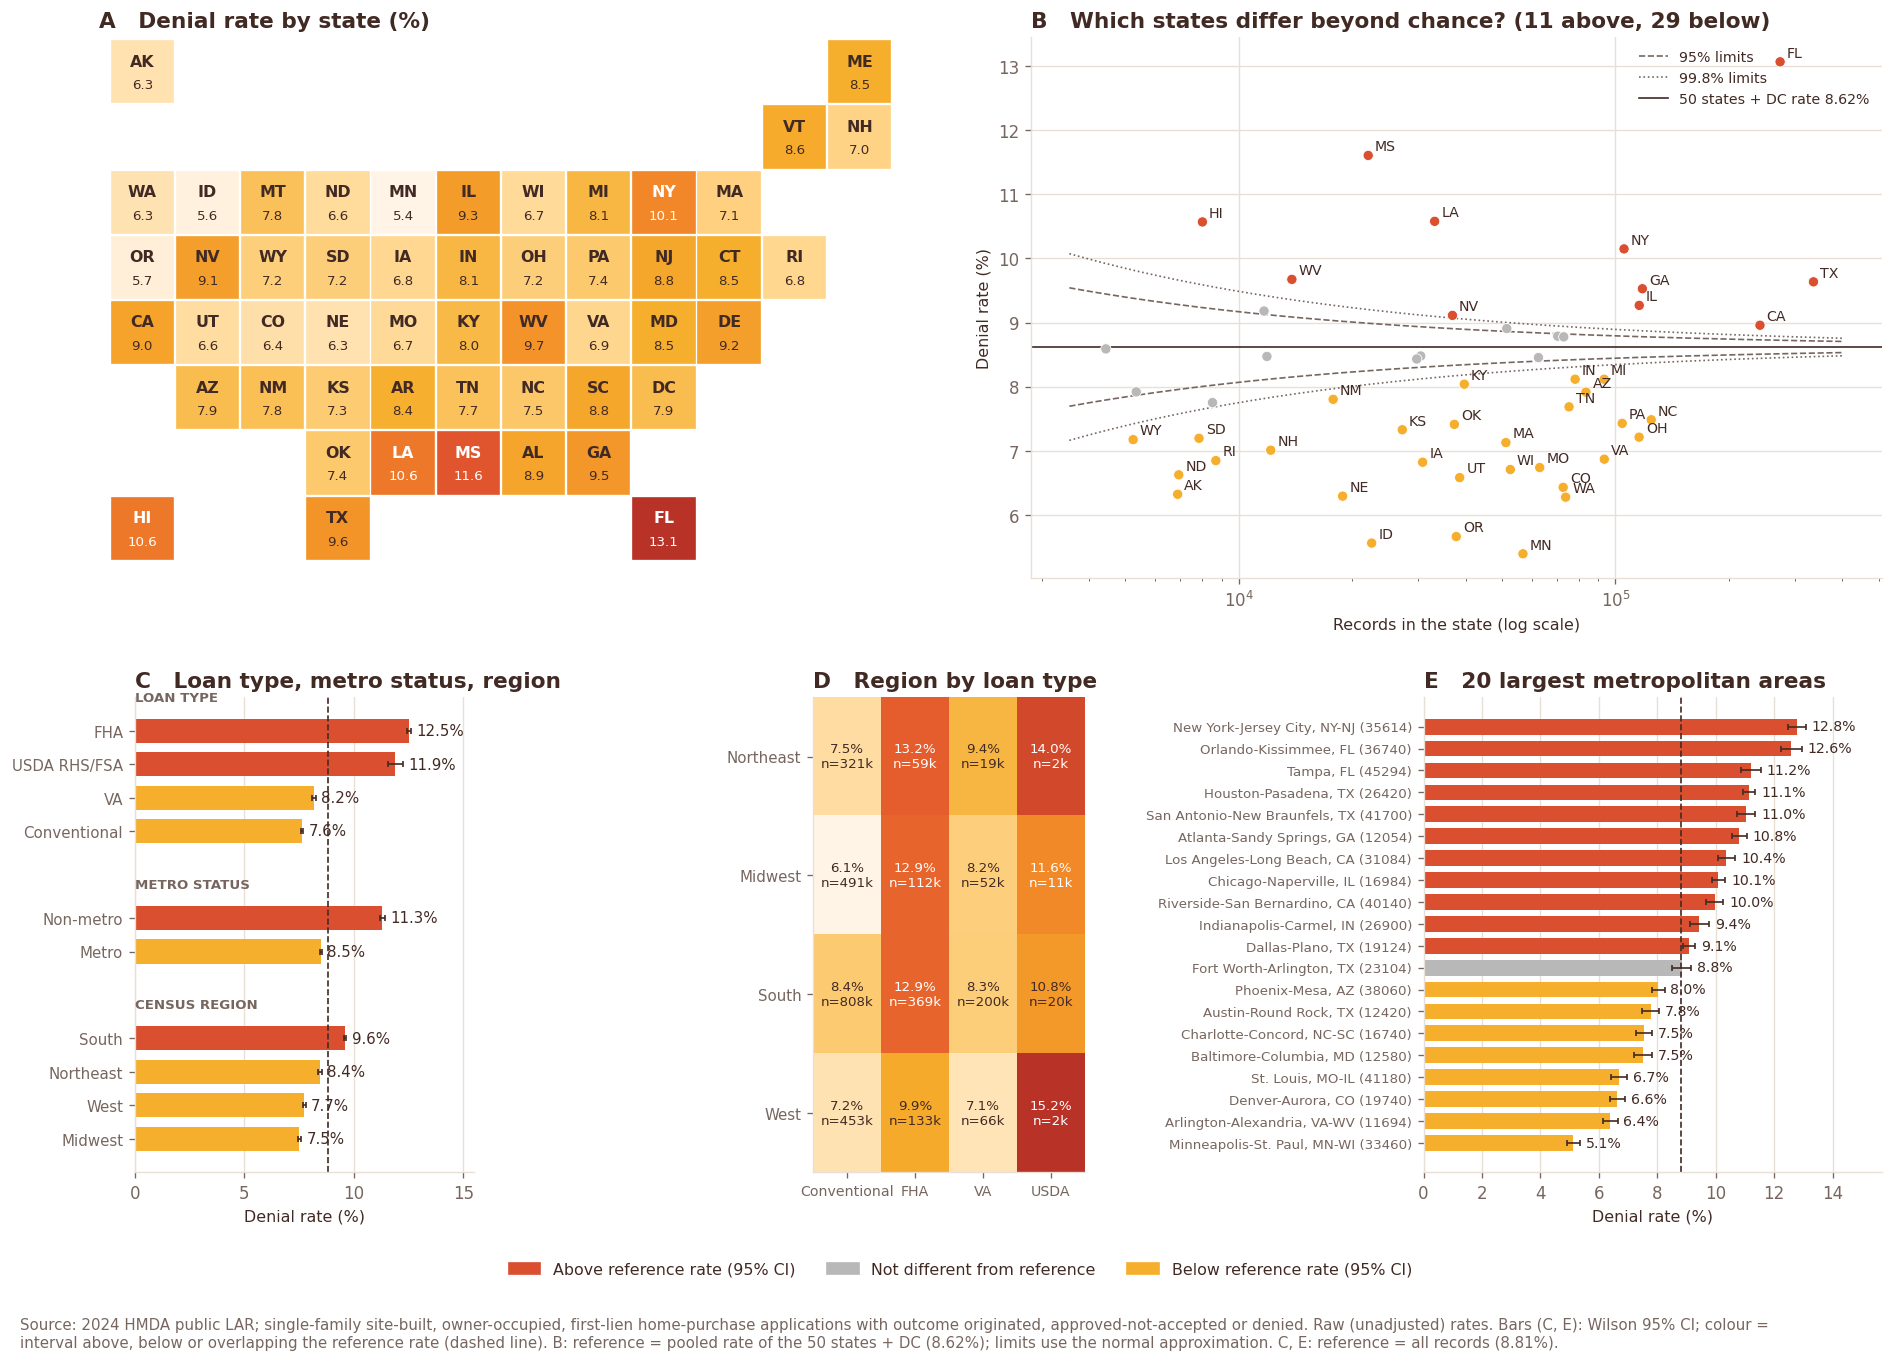

In [11]:
fig = plt.figure(figsize=(16, 11))
gsT = fig.add_gridspec(1, 2, top=0.96, bottom=0.55, left=0.04, right=0.98, wspace=0.12)
gsB = fig.add_gridspec(1, 3, top=0.46, bottom=0.10, left=0.07, right=0.98, width_ratios=[1, 0.8, 1.35], wspace=0.95)
HEAD = dict(loc="left", fontsize=13, fontweight="bold")

# A - tile map of denial rate by state
axA = fig.add_subplot(gsT[0, 0])
for st, (r, c) in GRID.items():
    if st not in rates.index:
        continue
    v = rates[st]
    axA.add_patch(Rectangle((c, -r), 0.94, 0.94, color=cmap(norm(v))))
    tc = "white" if norm(v) > 0.6 else TXT
    axA.text(c + 0.47, -r + 0.63, st, ha="center", va="center", fontsize=9.5, fontweight="bold", color=tc)
    axA.text(c + 0.47, -r + 0.27, f"{v:.1f}", ha="center", va="center", fontsize=8, color=tc)
axA.set_xlim(-0.2, 12.2); axA.set_ylim(-7.3, 1.0); axA.set_aspect("equal"); axA.axis("off")
axA.set_title("A   Denial rate by state (%)", **HEAD)

# B - funnel plot: which states differ from the national rate beyond chance
axB = fig.add_subplot(gsT[0, 1])
sf = states_only.copy()
z95, z998 = 1.959964, 3.090232
sef = np.sqrt(NAT_ST * (1 - NAT_ST) / sf["n"])
hi_ = sf["rate"] > NAT_ST + z998 * sef
lo_ = sf["rate"] < NAT_ST - z998 * sef
xs = np.logspace(np.log10(sf["n"].min() * 0.8), np.log10(sf["n"].max() * 1.2), 200)
for z, ls, lab in [(z95, "--", "95% limits"), (z998, ":", "99.8% limits")]:
    sx = np.sqrt(NAT_ST * (1 - NAT_ST) / xs)
    axB.plot(xs, (NAT_ST + z * sx) * 100, color=SEC, ls=ls, lw=1, label=lab)
    axB.plot(xs, (NAT_ST - z * sx) * 100, color=SEC, ls=ls, lw=1)
axB.axhline(NAT_ST * 100, color=TXT, lw=1, label=f"50 states + DC rate {NAT_ST:.2%}")
axB.scatter(sf["n"], sf["rate"] * 100, c=np.where(hi_, C_HI, np.where(lo_, C_LO, C_NS)), s=38, zorder=3,
            edgecolor="white", linewidth=0.5)
for st_, n_, r_ in zip(sf.loc[hi_ | lo_, "state_code"], sf.loc[hi_ | lo_, "n"], sf.loc[hi_ | lo_, "rate"]):
    axB.annotate(st_, (n_, r_ * 100), xytext=(4, 3), textcoords="offset points", fontsize=8.5)
axB.set_xscale("log"); axB.set_xlabel("Records in the state (log scale)", fontsize=9.5); axB.set_ylabel("Denial rate (%)", fontsize=9.5)
axB.legend(frameon=False, fontsize=8.5, loc="upper right")
axB.set_title(f"B   Which states differ beyond chance? ({int(hi_.sum())} above, {int(lo_.sum())} below)", **HEAD)

# C - loan type, metro status, Census region
axC = fig.add_subplot(gsB[0, 0])
parts = [("Loan type", by_loan.rename(columns={"loan_type_label": "grp"})),
         ("Metro status", by_metro.rename(columns={"metro_label": "grp"})),
         ("Census region", by_region[by_region["census_region"] != "Territory"].rename(columns={"census_region": "grp"}))]
ypos, yticks, ylabels = 0.0, [], []
for title, t in parts:
    axC.text(0.0, ypos, title.upper(), fontsize=8, fontweight="bold", color=SEC, va="center")
    ypos -= 1.0
    for _, r in t.sort_values("rate", ascending=False).iterrows():
        col = C_HI if r["ci_low"] > NAT else (C_LO if r["ci_high"] < NAT else C_NS)
        axC.barh(ypos, r["rate"] * 100, height=0.72, color=col,
                 xerr=[[(r["rate"] - r["ci_low"]) * 100], [(r["ci_high"] - r["rate"]) * 100]],
                 error_kw={"ecolor": TXT, "elinewidth": 1, "capsize": 2})
        axC.text(r["ci_high"] * 100 + 0.25, ypos, f"{r['rate']:.1%}", va="center", fontsize=9)
        yticks.append(ypos); ylabels.append(str(r["grp"]))
        ypos -= 1.0
    ypos -= 0.6
axC.axvline(NAT * 100, color=TXT, ls="--", lw=1)
axC.set_yticks(yticks); axC.set_yticklabels(ylabels, fontsize=9)
axC.set_xlim(0, 15.5); axC.set_xlabel("Denial rate (%)", fontsize=9.5); axC.grid(axis="y", visible=False)
axC.set_title("C   Loan type, metro status, region", **HEAD)

# D - region by loan type
axD = fig.add_subplot(gsB[0, 1])
imD = axD.imshow(pt.values * 100, cmap=HEATMAP_CMAP, aspect="auto")
axD.set_xticks(range(len(colsl))); axD.set_xticklabels([c_.replace("USDA RHS/FSA", "USDA") for c_ in colsl], fontsize=8.5)
axD.set_yticks(range(len(rows))); axD.set_yticklabels(rows, fontsize=9); axD.grid(False)
for i in range(len(rows)):
    for j in range(len(colsl)):
        v_, n_ = pt.values[i, j], pn.values[i, j]
        if np.isnan(v_):
            continue
        axD.text(j, i, f"{v_:.1%}\nn={n_/1000:,.0f}k", ha="center", va="center", fontsize=8,
                 color="white" if imD.norm(v_ * 100) > 0.6 else TXT)
axD.set_title("D   Region by loan type", **HEAD)

# E - 20 largest metropolitan areas
axE = fig.add_subplot(gsB[0, 2])
dE = by_msa_major.iloc[::-1]
yE = np.arange(len(dE))
axE.barh(yE, dE["rate"] * 100, height=0.72, color=sig_colors(dE),
         xerr=[(dE["rate"] - dE["ci_low"]) * 100, (dE["ci_high"] - dE["rate"]) * 100],
         error_kw={"ecolor": TXT, "elinewidth": 1, "capsize": 2})
for yi, (r_, h_) in enumerate(zip(dE["rate"], dE["ci_high"])):
    axE.text(h_ * 100 + 0.2, yi, f"{r_:.1%}", va="center", fontsize=8.5)
axE.axvline(NAT * 100, color=TXT, ls="--", lw=1)
axE.set_yticks(yE); axE.set_yticklabels([msa_label(x) for x in dE["msa_md_clean"]], fontsize=8)
axE.set_xlim(0, dE["ci_high"].max() * 100 * 1.2); axE.set_xlabel("Denial rate (%)", fontsize=9.5); axE.grid(axis="y", visible=False)
axE.set_title("E   20 largest metropolitan areas", **HEAD)

fig.legend(handles=LEGEND, loc="lower center", ncol=3, frameon=False, fontsize=9.5, bbox_to_anchor=(0.5, 0.01))
fig.text(0.01, -0.01, textwrap.fill(SOURCE + " Bars (C, E): Wilson 95% CI; colour = interval above, below or overlapping the reference rate (dashed line). "
         f"B: reference = pooled rate of the 50 states + DC ({NAT_ST:.2%}); limits use the normal approximation. C, E: reference = all records ({NAT:.2%}).", 230),
         fontsize=9, color=SEC, ha="left", va="top")
save(fig, "rq1_panel.png")

## Step 5e. Interactive state map (optional)
Geographic choropleth with hover details. Saved as an HTML file; the static tile-grid map above is the one used in the report.

In [12]:
import plotly.express as px
m = by_state[~by_state["state_code"].isin(["PR", "VI", "GU", "AS", "MP"])].copy()
m["rate_pct"] = (m["rate"] * 100).round(2)
fig = px.choropleth(m, locations="state_code", locationmode="USA-states", scope="usa",
                    color="rate_pct", color_continuous_scale=["#FFF4E6", "#FFD58A", "#F6AE2D", "#F28C28", "#E4572E", "#B83227"],   # Group 7 HEATMAP_CMAP
                    hover_data={"n": ":,", "rate_pct": ":.2f"},
                    labels={"rate_pct": "Denial rate (%)"},
                    title="Home-purchase denial rate by state, HMDA 2024")
fig.write_html(f"{FIG_DIR}/rq1_state_map.html")
try:
    fig.write_image(f"{FIG_DIR}/rq1_state_map.png", scale=2)
except Exception as e:
    pass   # static PNG export needs kaleido; the tile-grid map (Step 5a) is used for the report
fig.show()

## Step 6. Save the results

In [13]:
for name, t in [("overall", overall), ("by_state", by_state), ("by_region", by_region),
                ("state_missing_summary", pd.DataFrame({"n": [len(state_missing)], "denied": [int(state_missing["denied"].sum())]})), ("by_metro", by_metro), ("by_loan_type", by_loan), ("by_msa", by_msa), ("by_msa_major20", by_msa_major), ("region_by_loan_type", cross), ("by_state_funnel", s)]:
    t.to_csv(f"{RESULTS}/rq1_{name}.csv", index=False)
with open(f"{RESULTS}/rq1_pandas_timing.json", "w") as fh:
    json.dump({"load_seconds": round(t_load, 2), "compute_seconds": round(t_compute, 2)}, fh)
print("Saved CSV tables, charts and timing to", RESULTS)

Saved CSV tables, charts and timing to /content/drive/MyDrive/hmda/results
